<a href="https://colab.research.google.com/github/Muredepadure/adversarial-ml-evasion/blob/main/pgd_hsj_evasion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [2]:
!pip install adversarial-robustness-toolbox

In [3]:
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import datasets, transforms

device = torch.device("cuda")
tfm = transforms.ToTensor()  # pixels scaled to [0,1]

train = datasets.MNIST(root="./data", train=True,  download=True, transform=tfm)
test  = datasets.MNIST(root="./data", train=False, download=True, transform=tfm)
train_loader = torch.utils.data.DataLoader(train, batch_size=128, shuffle=True)
test_loader  = torch.utils.data.DataLoader(test,  batch_size=256)
print("train:", len(train), " test:", len(test))

train: 60000  test: 10000


In [4]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, 1)
        self.conv2 = nn.Conv2d(32, 64, 3, 1)
        self.fc1 = nn.Linear(9216, 128)
        self.fc2 = nn.Linear(128, 10)
    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)        # raw logits (no softmax)

model = Net().to(device)
print(model)

Net(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=9216, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [5]:
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

model.train()
for epoch in range(2):                         # 2 passes is enough for ~99%
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = F.cross_entropy(model(x), y)
        loss.backward()
        opt.step()
    print(f"epoch {epoch+1} done, last batch loss {loss.item():.4f}")

epoch 1 done, last batch loss 0.0568
epoch 2 done, last batch loss 0.0238


In [6]:
model.eval()
correct = total = 0
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        pred = model(x).argmax(1)
        correct += (pred == y).sum().item()
        total += y.size(0)
print(f"clean test accuracy: {100*correct/total:.2f}%")

clean test accuracy: 98.58%


In [7]:
def pgd_attack(model, images, labels, eps=0.3, alpha=0.01, iters=40):
    images, labels = images.to(device), labels.to(device)
    ori = images.clone().detach()                 # remember the original

    # start from a random point inside the eps-ball
    adv = ori + torch.empty_like(ori).uniform_(-eps, eps)
    adv = torch.clamp(adv, 0, 1).detach()

    for i in range(iters):
        adv.requires_grad_(True)
        loss = F.cross_entropy(model(adv), labels)   # loss w.r.t. CURRENT adv
        grad = torch.autograd.grad(loss, adv)[0]     # gradient of loss w.r.t. input

        # ---- YOUR LINE: take one gradient-ASCENT step of size alpha ----
        # push adv in the direction that INCREASES the loss, using the sign of grad
        adv = adv.detach() + torch.sign(grad) * alpha

        # project back into the eps-ball around the original, then to valid pixels
        adv = torch.min(torch.max(adv, ori - eps), ori + eps)
        adv = torch.clamp(adv, 0, 1).detach()

    return adv

In [8]:
# grab one batch of clean test images
x, y = next(iter(test_loader))
x, y = x.to(device), y.to(device)

# clean accuracy on this batch
model.eval()
clean_pred = model(x).argmax(1)
clean_acc = (clean_pred == y).float().mean().item()

# craft adversarial versions and re-measure
x_adv = pgd_attack(model, x, y, eps=0.3, alpha=0.01, iters=40)
adv_pred = model(x_adv).argmax(1)
adv_acc = (adv_pred == y).float().mean().item()

print(f"clean accuracy on this batch: {100*clean_acc:.2f}%")
print(f"accuracy after PGD attack:    {100*adv_acc:.2f}%")

clean accuracy on this batch: 99.22%
accuracy after PGD attack:    0.00%


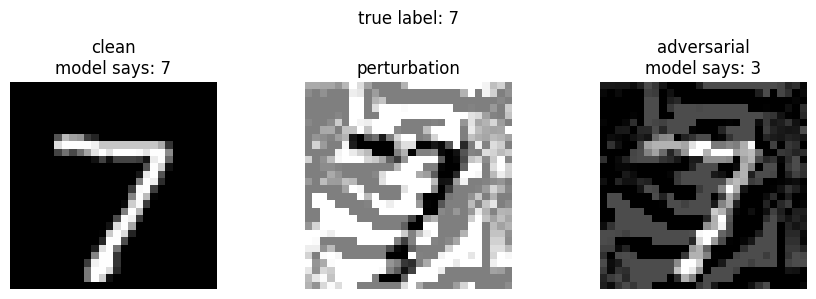

In [9]:
import matplotlib.pyplot as plt

# pick the first image in the batch
i = 0
clean_img = x[i, 0].detach().cpu()
adv_img   = x_adv[i, 0].detach().cpu()
pert      = (adv_img - clean_img)

true_label  = y[i].item()
clean_guess = model(x[i:i+1]).argmax(1).item()
adv_guess   = model(x_adv[i:i+1]).argmax(1).item()

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
ax[0].imshow(clean_img, cmap="gray");          ax[0].set_title(f"clean\nmodel says: {clean_guess}")
ax[1].imshow(pert, cmap="gray");               ax[1].set_title("perturbation")
ax[2].imshow(adv_img, cmap="gray");            ax[2].set_title(f"adversarial\nmodel says: {adv_guess}")
for a in ax: a.axis("off")
plt.suptitle(f"true label: {true_label}")
plt.tight_layout(); plt.show()

In [12]:
from art.estimators.classification import PyTorchClassifier
from art.attacks.evasion import HopSkipJump
import numpy as np

classifier = PyTorchClassifier(
    model=model,
    loss=nn.CrossEntropyLoss(),
    optimizer=torch.optim.Adam(model.parameters(), lr=1e-3),
    input_shape=(1, 28, 28),
    nb_classes=10,
    clip_values=(0.0, 1.0),
)

x_test_small = x[:10].cpu().numpy().astype("float32")
y_test_small = y[:10].cpu().numpy()
preds = classifier.predict(x_test_small).argmax(1)
print("ART clean predictions:", preds)
print("true labels:          ", y_test_small)

ART clean predictions: [7 2 1 0 4 1 4 9 5 9]
true labels:           [7 2 1 0 4 1 4 9 5 9]


In [14]:
import numpy as np
from art.estimators.classification import PyTorchClassifier
from art.attacks.evasion import HopSkipJump

model.float()  # model is float32

# wrapper: cast any incoming tensor to float32 before the real model
class CastWrapper(nn.Module):
    def __init__(self, inner):
        super().__init__()
        self.inner = inner
    def forward(self, t):
        return self.inner(t.float())   # force float32 regardless of input dtype

wrapped = CastWrapper(model).to(device)

classifier = PyTorchClassifier(
    model=wrapped,
    loss=nn.CrossEntropyLoss(),
    optimizer=torch.optim.Adam(wrapped.parameters(), lr=1e-3),
    input_shape=(1, 28, 28),
    nb_classes=10,
    clip_values=(0.0, 1.0),
)

n_images = 5
x_hsj = x[:n_images].cpu().numpy().astype("float32")
y_hsj = y[:n_images].cpu().numpy()

attack = HopSkipJump(
    classifier=classifier, targeted=False,
    max_iter=30, max_eval=1000, init_eval=100, verbose=True,
)

x_hsj_adv = attack.generate(x=x_hsj)
print("HSJ attack complete.")

HopSkipJump:   0%|          | 0/5 [00:00<?, ?it/s]

HSJ attack complete.


In [15]:
import numpy as np
clean_preds = classifier.predict(x_hsj).argmax(1)
adv_preds   = classifier.predict(x_hsj_adv).argmax(1)
l2 = np.linalg.norm((x_hsj_adv - x_hsj).reshape(n_images, -1), axis=1)

print("true labels:        ", y_hsj)
print("clean predictions:  ", clean_preds)
print("HSJ predictions:    ", adv_preds)
print("fooled:             ", (adv_preds != clean_preds))
print("avg L2 perturbation:", l2.mean().round(3))


true labels:         [7 2 1 0 4]
clean predictions:   [7 2 1 0 4]
HSJ predictions:     [3 8 8 2 9]
fooled:              [ True  True  True  True  True]
avg L2 perturbation: 2.074


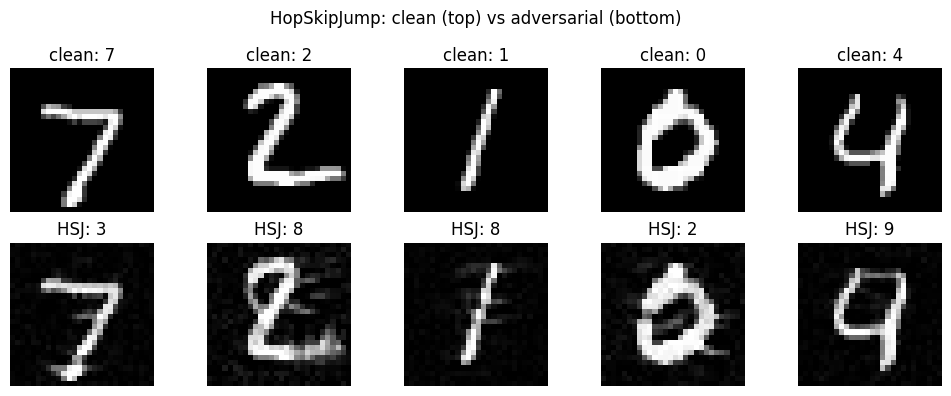

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, n_images, figsize=(2*n_images, 4))
for i in range(n_images):
    ax[0, i].imshow(x_hsj[i, 0], cmap="gray")
    ax[0, i].set_title(f"clean: {clean_preds[i]}")
    ax[1, i].imshow(x_hsj_adv[i, 0], cmap="gray")
    ax[1, i].set_title(f"HSJ: {adv_preds[i]}")
    ax[0, i].axis("off"); ax[1, i].axis("off")
plt.suptitle("HopSkipJump: clean (top) vs adversarial (bottom)")
plt.tight_layout(); plt.show()

In [17]:
# PGD on the same 5 images, for a fair comparison
x_cmp = x[:n_images]
y_cmp = y[:n_images]
x_cmp_pgd = pgd_attack(model, x_cmp, y_cmp, eps=0.3, alpha=0.01, iters=40)

pgd_preds = model(x_cmp_pgd).argmax(1).cpu().numpy()
pgd_l2 = np.linalg.norm(
    (x_cmp_pgd.detach().cpu().numpy() - x_cmp.cpu().numpy()).reshape(n_images, -1), axis=1
)

print("=== PGD (white-box) vs HSJ (black-box) on the same 5 images ===\n")
print(f"{'':20} {'PGD':>12} {'HSJ':>12}")
print(f"{'model access':20} {'gradients':>12} {'labels only':>12}")
print(f"{'images fooled':20} {f'{(pgd_preds != y_cmp.cpu().numpy()).sum()}/5':>12} {f'{(adv_preds != clean_preds).sum()}/5':>12}")
print(f"{'avg L2 perturbation':20} {pgd_l2.mean():>12.3f} {l2.mean():>12.3f}")
print(f"{'queries per image':20} {'~40 (grad)':>12} {'~1000s':>12}")

=== PGD (white-box) vs HSJ (black-box) on the same 5 images ===

                              PGD          HSJ
model access            gradients  labels only
images fooled                 5/5          5/5
avg L2 perturbation         5.485        2.074
queries per image      ~40 (grad)       ~1000s


In [18]:
# re-save the two key figures as PNGs to download for the repo
# (run your PGD visualization cell first if the figure isn't current)
fig.savefig("hsj_comparison.png", dpi=120, bbox_inches="tight")
print("saved hsj_comparison.png — download it from the file panel (left sidebar, folder icon)")

saved hsj_comparison.png — download it from the file panel (left sidebar, folder icon)
